# SafeInvest：主框架与准入收敛

这是研究 companion，不是比赛论文。当前保留原有全策略有限族受约束学习框架，并对其**已经选定**的策略增加固定 own-inner same-U B 准入门槛。旧β、η／控制器、Q1目标、top-E逻辑和原拒绝均不改变，没有新拟合、重新排名、兜底或救回旧拒绝。

这项主框架采用和额外guard是**后续公开的开发选择**。两次近期简化实验按各自冻结规则失败，结果继续保留；不能追认某个最终赢家一直预声明。相同原120条市场路径已被反复使用，不产生新的盲测或确认性安全证书。

五次重复在额外 guard 后的自动路径记录数为 **0、24、0、24、48 / 每次原120条**，对应完整期限事件为 **NULL（0自动）；5/24；NULL（0自动）；1/24；3/48**。全120最终拟合为 **`execution_review`**，原因 `inner_risk_exceeds_same_U_B`。主框架已收敛，自动部署成功尚未成立。

## 1. 当前来源和独立审计门槛

本笔记只读已经完成、独立审计通过的产物，并验证审计绑定当前父manifest、当前源码／输入／输出SHA以及起止快照一致。父实验的完整审计和当前文件同样核验。只对字节流计算SHA，不解析原市场CSV，不载入收益数组、模拟器、拟合器或选择器。原121—180曾在早期V1接触过，本轮不读取，也不把它们称新的盲测。

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display
ROOT=next(p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents] if (p/'docs/global_policy_admission_protocol.json').is_file())
sys.path.insert(0,str(ROOT/'scripts'))
import build_final_model_notebook as companion
ready=companion.require_complete(ROOT)
tables=companion.load_tables(ROOT)
figures=companion.readj(ROOT/companion.FIGURES/'manifest.json')
assert figures['status']=='complete' and figures['visual_review_confirmed'] is True
for key in ('source_sha256','input_artifact_sha256','outputs_sha256'):companion.check_mapping(ROOT,figures[key])
SOURCE_NOTE=companion.SOURCE_NOTE;POLICY=companion.POLICY;OLD=companion.OLD;B=companion.B;EQUAL=companion.EQUAL
plot_style=companion.plot_style
def show(frame,formats=None):display(frame.style.format(formats or {},na_rep='NULL').hide(axis='index'))
print('完整产物、独立审计绑定和当前文件SHA检查通过。只读保存结果，没有新拟合或市场解析。')

完整产物、独立审计绑定和当前文件SHA检查通过。只读保存结果，没有新拟合或市场解析。


## 2. 先固定数学对象，再解释技术参数

客户C沿用原$H=30,L=0.40$，初始票据财富100。真实购买力为$R_t=W_t/\prod_{s=1}^{t}(1+\pi_s)$，名义财富已扣实际费用；$D_H=\max_{0\le t\le H}(1-R_t/\max_{s\le t}R_s)$。完整期限事件是$D_H>L$，不是单年概率，也没有重置历史。

核心增长目标是$G_H(\pi)=E[\log(R_H/100)]/H$；风险服务基准是$P(D_H>L)\le\alpha$，声明$\alpha=0.10$。它不是问卷识别的风险偏好、题目强制概率或统计保证。$L$是客户问卷阈值，也不是财富保证。报告同时保留题目要求的CAGR中位数/P10和MDD中位数/P90；这些分位数不是置信区间。

实现保留一个有限因果策略族。每个训练β下，在原9个技术控制器中选平均年化log增长最高、且$k_j\le\min(k_B,\lfloor\beta n\rfloor)$的候选。β属于固定网格$\{0,.025,.05,.075,.10\}$，它与η都不是客户问卷识别量。

内层仅保留自身自动子群有证据、且满足原绝对风险门槛的β程序，先最大化自动路径覆盖，再按同一全局$10^{-12}$增长容差保留top集合$E$。最终只在升序$E$内找原完整训练可行选择。它是带覆盖优先服务逻辑的有限族过程，不是对所有可能策略的纯增长全局最优解。

## 3. η只生成控制器，费用只计一次

决策前只使用实际到$t-1$的余额、CPI、历史峰值、运行MDD和原期限。用自己的训练联合路径calendar后缀，评估当前hold或paid restore，并在其后使用冻结年度B直到该分支首次超限、以后持有。经验fan、B续行近似、实际下一年重规划均为明确假设，不是校准条件概率或精确动态规划。

$Q_g$是至原$H$的净真实购买力**总log增长**，已经包含当前与续行费用及其对pending路径的影响。有限η使用
$$\Delta Q_g-H\eta\,\Delta\widehat p>10^{-12},\quad\Delta\widehat p=(k_R-k_H)/N.$$
η是冻结有限族中生成策略的技术索引，不是问卷风险厌恶、货币交换意愿、KKT乘子或精确对偶价格。第9个`risk_first`为单独的整数量词序规则：先较少事件，再净增长，并非数值无穷大运算。

若可选恢复的$\Delta Q_g>10^{-12}$，是模型内费后增长改善；若不为正，必须严格降低预测事件计数，由风险项解释其代价。严格$\Delta Q_g<-10^{-12}$另标增长牺牲，不能称正现金利润、必要或唯一可行动作。正局部分数仍不证明完整策略风险合格。

当前恢复费用由$C=0.0025\sum_a[(W-C)w_a-x_a]_+$自融资求解，交易后总财富$W-C$。报价可单列，但不能再从已净值化$Q_g$扣一次。由于后续分支历史／pending／费用可能不同，一般不能把完整B续行优势简化成无费优势减当前费。初配强制并收费；原模式的初配／pending不伪造可选经济证据，真实首次超限后永久持有，无终端清算费。

## 4. 新准入只检查旧已选β的自身U

只有旧结果已经自动的fit才可能获准。取它**原最终已选β**的四个内层预测块；各块仍用该内层自己的目标和原η选择，不能把最终refit的η倒施给内层。$U$恰是这些记录中的原自动ID，完整原内层分母继续保留。

新guard固定要求$|U|>0$、$k_\pi(U)\le\lfloor0.10|U|\rfloor$，且$k_\pi(U)\le k_B(U)$。B逐job、原ID、Q1目标、静态γ和原H/L/费用/pending约定匹配。失败后整组24外层路径或全120路径统一Review、金融字段NULL，不尝试另一个β、η、目标、架构或B补值。

这个准入决定在该fit外层收益前，只用其旧内层证据；但guard和主框架采用的研究开发历史已有适应性。因而不能把新冻结称新市场信息或独立确认试验。

In [2]:
admission=tables['admission']
show(admission[['repeat_id','outer_fold','original_execution_status','selected_beta','selected_candidate_order',
    'auto_inner_n','k_inner','k_B_same_U','absolute_cap','final_automated','execution_status','execution_reason']])

repeat_id,outer_fold,original_execution_status,selected_beta,selected_candidate_order,auto_inner_n,k_inner,k_B_same_U,absolute_cap,final_automated,execution_status,execution_reason
1,1,execution_review,NULL,NULL,NULL,NULL,NULL,NULL,False,execution_review,no_refit_feasible_beta_in_top_E
1,2,execution_review,NULL,NULL,NULL,NULL,NULL,NULL,False,execution_review,no_top_inner_beta
1,3,execution_review,NULL,NULL,NULL,NULL,NULL,NULL,False,execution_review,no_refit_feasible_beta_in_top_E
1,4,execution_review,NULL,NULL,NULL,NULL,NULL,NULL,False,execution_review,no_top_inner_beta
1,5,execution_review,NULL,NULL,NULL,NULL,NULL,NULL,False,execution_review,no_top_inner_beta
2,1,execution_review,NULL,NULL,NULL,NULL,NULL,NULL,False,execution_review,no_refit_feasible_beta_in_top_E
2,2,automated,0.050000,5.000000,96.000000,7.000000,7.000000,9.000000,True,automated,NULL
2,3,execution_review,NULL,NULL,NULL,NULL,NULL,NULL,False,execution_review,no_top_inner_beta
2,4,execution_review,NULL,NULL,NULL,NULL,NULL,NULL,False,execution_review,no_top_inner_beta
2,5,automated,0.075000,5.000000,96.000000,9.000000,6.000000,9.000000,False,execution_review,inner_risk_exceeds_same_U_B


## 5. 五次重复：覆盖收缩与相同外层ID事件

左图比较原学习程序与额外guard后的自动路径记录数。右图只在每次重复的外层获准集合$A$上逐ID配对模型和B，$A$不同于内层guard集合$U$。零准入的事件率保留NULL。重复共享同一原120条路径、拟合训练集合重叠；不能把5次当600条独立市场或把路径记录称新增客户。内层guard通过也不能保证该外层小子群事件率不超过10%。

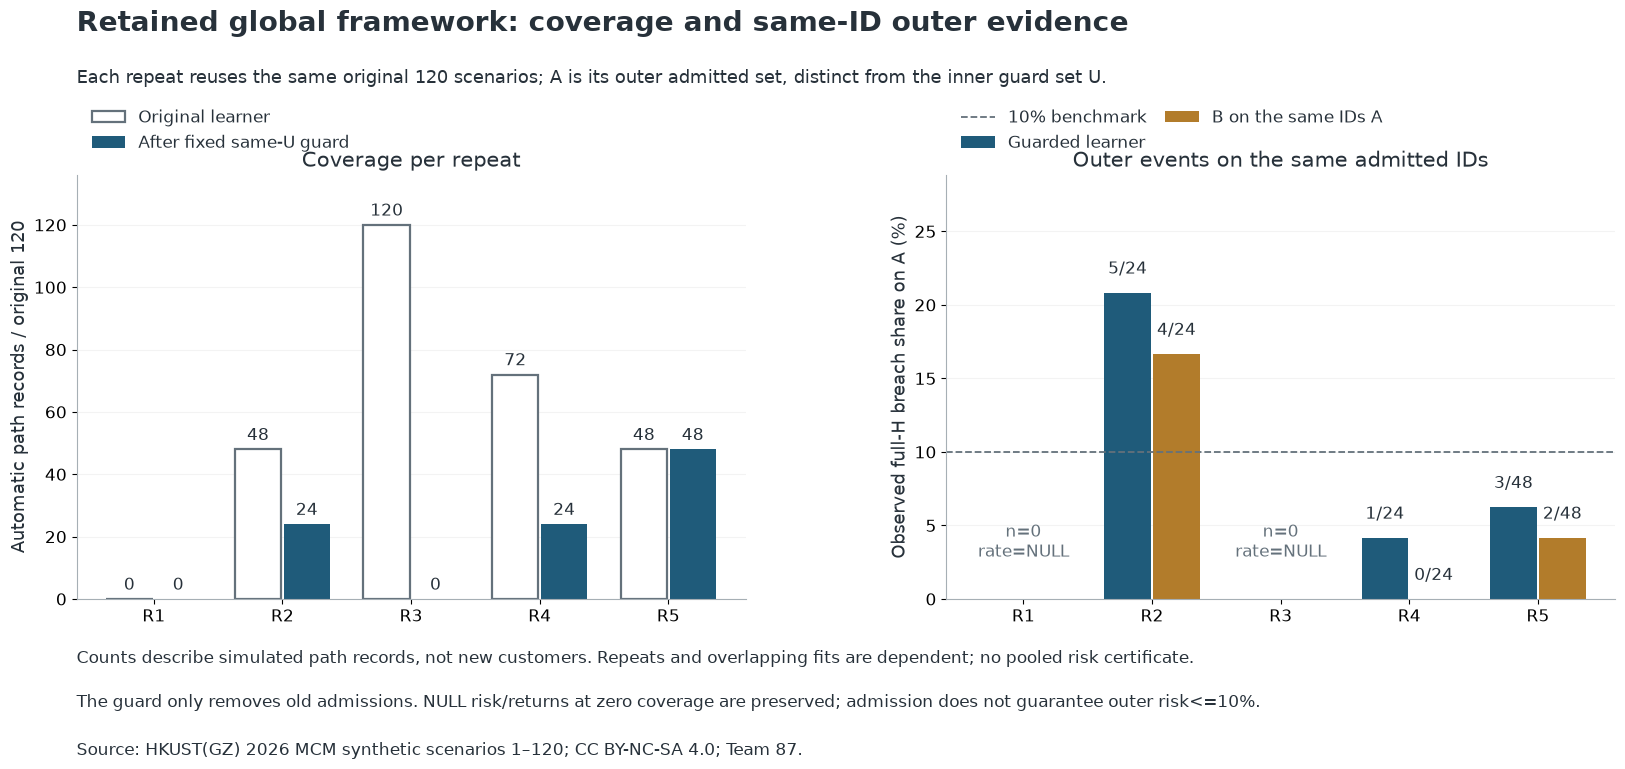

In [3]:
def plot_repeats(repeat):
    import numpy as np
    import matplotlib.pyplot as plt
    plot_style();fig,axes=plt.subplots(1,2,figsize=(17,8));fig.subplots_adjust(left=.065,right=.97,bottom=.23,top=.76,wspace=.3)
    x=np.arange(5);left,right=axes
    left.bar(x-.19,repeat.original_auto_n,.36,color='white',edgecolor='#64717b',linewidth=1.6,label='Original learner')
    left.bar(x+.19,repeat.final_auto_n,.36,color='#1f5b7a',label='After fixed same-U guard')
    for j,row in enumerate(repeat.itertuples()):
        left.text(j-.19,row.original_auto_n+3,str(row.original_auto_n),ha='center',fontsize=12)
        left.text(j+.19,row.final_auto_n+3,str(row.final_auto_n),ha='center',fontsize=12)
    left.set(xticks=x,xticklabels=[f'R{i}' for i in range(1,6)],xlim=(-.6,4.6),ylim=(0,136),ylabel='Automatic path records / original 120',title='Coverage per repeat')
    left.legend(loc='upper left',bbox_to_anchor=(0,1.19),frameon=False)
    valid=repeat.final_auto_n.gt(0)
    for offset,column,count_column,label,color in [(-.19,'model_rate','model_k','Guarded learner','#1f5b7a'),(.19,'B_same_A_rate','B_same_A_k','B on the same IDs A','#b27c2b')]:
        heights=repeat.loc[valid,column].to_numpy(float)*100
        right.bar(x[valid]+offset,heights,.36,color=color,label=label)
        for j,height in zip(x[valid],heights):
            row=repeat.iloc[j];right.text(j+offset,height+1.3,f'{int(row[count_column])}/{int(row.final_auto_n)}',ha='center',fontsize=12)
    upper=max([28.]+[float(v)*100+8 for v in repeat[['model_rate','B_same_A_rate']].to_numpy().ravel() if v==v])
    for j in x[~valid]:right.text(j,2.5,'n=0\nrate=NULL',ha='center',va='bottom',fontsize=12,color='#64717b')
    right.axhline(10,color='#64717b',linestyle='--',linewidth=1.3,label='10% benchmark')
    right.set(xticks=x,xticklabels=[f'R{i}' for i in range(1,6)],xlim=(-.6,4.6),ylim=(0,upper),ylabel='Observed full-H breach share on A (%)',title='Outer events on the same admitted IDs')
    right.legend(loc='upper left',bbox_to_anchor=(0,1.19),frameon=False,ncol=2,columnspacing=1.1)
    for ax in axes:ax.spines[['top','right']].set_visible(False);ax.grid(axis='y',alpha=.15);ax.set_axisbelow(True)
    fig.text(.065,.94,'Retained global framework: coverage and same-ID outer evidence',fontsize=20,weight='bold')
    fig.text(.065,.875,'Each repeat reuses the same original 120 scenarios; A is its outer admitted set, distinct from the inner guard set U.',fontsize=13)
    fig.text(.065,.15,'Counts describe simulated path records, not new customers. Repeats and overlapping fits are dependent; no pooled risk certificate.',fontsize=12)
    fig.text(.065,.095,'The guard only removes old admissions. NULL risk/returns at zero coverage are preserved; admission does not guarantee outer risk<=10%.',fontsize=12)
    fig.text(.065,.035,SOURCE_NOTE,fontsize=12)
    return fig

fig=plot_repeats(tables['repeat'])
display(fig)
import matplotlib.pyplot as plt
plt.close(fig)

In [4]:
show(tables['repeat'],{'model_rate':'{:.2%}','B_same_A_rate':'{:.2%}'})

repeat_id,original_n,original_auto_n,final_auto_n,model_k,B_same_A_k,model_rate,B_same_A_rate,mean_delta_log_growth,mean_delta_mdd,mean_delta_nominal_fees
1,120,0,0,NULL,NULL,NULL,NULL,NULL,NULL,NULL
2,120,48,24,5.000000,4.000000,20.83%,16.67%,0.003268,0.019929,-0.246067
3,120,120,0,NULL,NULL,NULL,NULL,NULL,NULL,NULL
4,120,72,24,1.000000,0.000000,4.17%,0.00%,0.002726,0.028185,-0.368332
5,120,48,48,3.000000,2.000000,6.25%,4.17%,0.003413,0.020730,-0.382022


## 6. 失败的简化规则与全开发拟合分开呈现

以下左图全部是完整120条训练路径的策略事件计数：一年正净增长gate、固定局部α规则、保留的旧global已选控制器。它们不是外层验证收益排名，也没有从本图另选赢家。两个简化规则失败并不能证明所有安全盈利策略不存在；局部正经济性或每个状态局部10%不是原完整策略机会约束的唯一实现。

右图是保留框架已选β的自身**内层预测**事件，与逐ID同U的B相比。即使样本数也等于120，它与左图完整训练是不同阶段、不同预测过程。额外same-U比较失败仍应Review。全120最终结果为in-sample，不能当第六次验证。

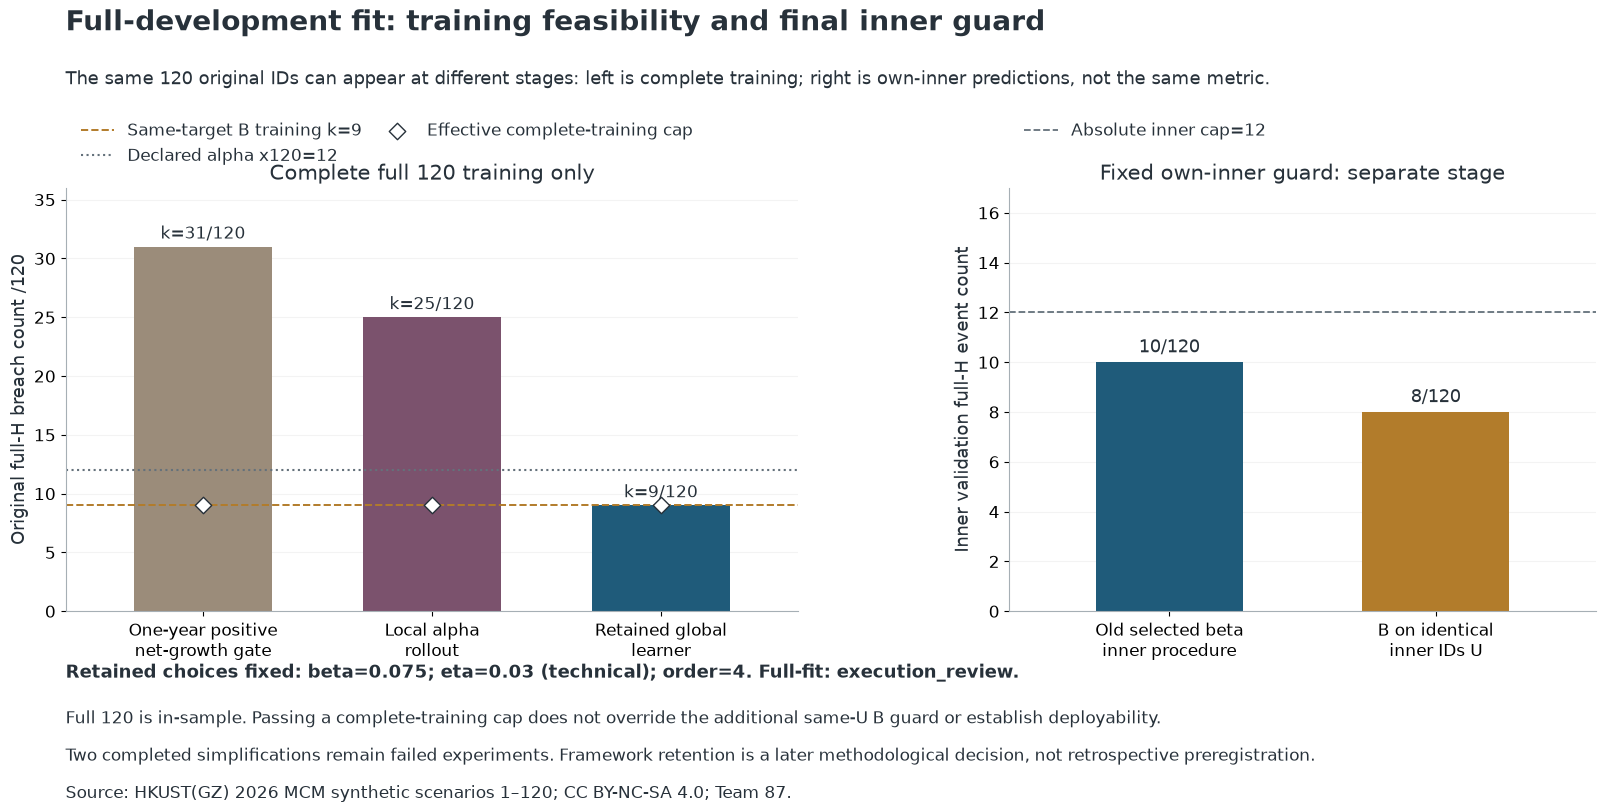

In [5]:
def plot_full_stages(comparison,full,old_choice):
    import numpy as np
    import matplotlib.pyplot as plt
    plot_style();fig,axes=plt.subplots(1,2,figsize=(17,8.3),gridspec_kw={'width_ratios':[1.25,1]})
    fig.subplots_adjust(left=.065,right=.965,bottom=.25,top=.76,wspace=.32);left,right=axes;x=np.arange(3)
    colors=['#9b8c7a','#7b526d','#1f5b7a'];labels=['One-year positive\nnet-growth gate','Local alpha\nrollout','Retained global\nlearner']
    for j,row in enumerate(comparison.itertuples()):
        if row.training_k==row.training_k:
            left.bar(j,row.training_k,.6,color=colors[j]);left.text(j,row.training_k+.7,f'k={int(row.training_k)}/120',ha='center',fontsize=12)
        else:left.text(j,1,'not selected\nk=NULL',ha='center',fontsize=12)
        if row.training_cap==row.training_cap:left.scatter(j,row.training_cap,marker='D',s=70,facecolors='white',edgecolors='#27313a',zorder=4)
    B_values=comparison.B_training_k.dropna().unique()
    if len(B_values)==1:left.axhline(B_values[0],color='#b27c2b',linestyle='--',linewidth=1.4,label=f'Same-target B training k={int(B_values[0])}')
    left.axhline(12,color='#64717b',linestyle=':',linewidth=1.5,label='Declared alpha x120=12')
    left.scatter([],[],marker='D',s=70,facecolors='white',edgecolors='#27313a',label='Effective complete-training cap')
    left.set(xticks=x,xticklabels=labels,xlim=(-.6,2.6),ylim=(0,max([36]+list(comparison.training_k.dropna()+5))),ylabel='Original full-H breach count /120',title='Complete full 120 training only')
    left.legend(loc='upper left',bbox_to_anchor=(0,1.19),frameon=False,ncol=2,columnspacing=1.1)
    n=full['auto_inner_n'];k=full['k_inner'];kb=full['k_B_same_U'];cap=full['absolute_cap']
    if n is not None and n==n and int(n)>0:
        vals=[int(k),int(kb)];right.bar([0,1],vals,.55,color=['#1f5b7a','#b27c2b'])
        for j,value in enumerate(vals):right.text(j,value+.4,f'{value}/{int(n)}',ha='center',fontsize=13)
        right.axhline(cap,color='#64717b',linestyle='--',linewidth=1.3,label=f'Absolute inner cap={int(cap)}')
        right.set(xticks=[0,1],xticklabels=['Old selected beta\ninner procedure','B on identical\ninner IDs U'],xlim=(-.6,1.6),ylim=(0,max(vals+[int(cap)])+5),ylabel='Inner validation full-H event count',title='Fixed own-inner guard: separate stage')
        right.legend(loc='upper left',bbox_to_anchor=(0,1.19),frameon=False)
    else:
        right.axis('off');right.text(.5,.5,'Original learner unavailable\nInner guard evidence=NULL',ha='center',va='center',transform=right.transAxes,fontsize=15)
    for ax in axes:ax.spines[['top','right']].set_visible(False);ax.grid(axis='y',alpha=.15);ax.set_axisbelow(True)
    beta=old_choice['selected_beta'];order=old_choice['selected_candidate_order'];state=full['execution_status']
    fig.text(.065,.95,'Full-development fit: training feasibility and final inner guard',fontsize=20,weight='bold')
    fig.text(.065,.885,'The same 120 original IDs can appear at different stages: left is complete training; right is own-inner predictions, not the same metric.',fontsize=13)
    fig.text(.065,.17,f'Retained choices fixed: beta={beta}; eta={full["eta_technical_display"]} (technical); order={order}. Full-fit: {state}.',fontsize=13,weight='bold')
    fig.text(.065,.115,'Full 120 is in-sample. Passing a complete-training cap does not override the additional same-U B guard or establish deployability.',fontsize=12)
    fig.text(.065,.07,'Two completed simplifications remain failed experiments. Framework retention is a later methodological decision, not retrospective preregistration.',fontsize=12)
    fig.text(.065,.025,SOURCE_NOTE,fontsize=12)
    return fig

fig=plot_full_stages(tables['comparison'],tables['full'],tables['old_full_choice'])
display(fig)
plt.close(fig)

In [6]:
show(tables['comparison'])
show(pd.DataFrame([{k:tables['full'][k] for k in ['selected_beta','selected_candidate_order','auto_inner_n','k_inner','k_B_same_U','absolute_cap','execution_status','execution_reason']}]))

method,training_n,training_k,training_cap,B_training_k,service_status,detail
One-year positive net gate,120,31.000000,9,9,execution_review,Completed failed simplification; unchanged
Local alpha rollout,120,25.000000,9,9,execution_review,Completed failed simplification; unchanged
Retained global learner,120,9.000000,9,9,execution_review,Old chosen controller + additional same-U guard


selected_beta,selected_candidate_order,auto_inner_n,k_inner,k_B_same_U,absolute_cap,execution_status,execution_reason
0.075000,4.000000,120.000000,10.000000,8.000000,12.000000,execution_review,inner_risk_exceeds_same_U_B


## 7. 题目要求的金融摘要及其条件分母

这里只展示最终获准子群的保存财务记录；参考策略为假设性参照，Review不以B补值。中位数和P10/P90均直接在当前条件自动路径上计算，离散分位数使用`inverted_cdf`。自动人群变化后，不同子群均值或分位数相减不能解释成策略因果收益。全开发0号scope与5次重复分开；不合并、平均分位数或生成IID置信证书。

In [7]:
summary=tables['summary']
names={POLICY:'保留程序+固定guard',B:'同目标年度B参照',EQUAL:'等权年度参照'}
for scope in ['outer_oof','in_sample_full120']:
    frame=summary.loc[summary.scope.eq(scope),['repeat_id','policy','original_n','assigned_n','breach_count','conditional_breach_probability','median_cagr','p10_cagr','median_mdd','p90_mdd','mean_fees','mean_trade_fraction']].copy()
    frame['policy']=frame.policy.map(names)
    print(scope)
    show(frame,{k:'{:.2%}' for k in ['conditional_breach_probability','median_cagr','p10_cagr','median_mdd','p90_mdd','mean_trade_fraction']}|{'mean_fees':'{:.4f}'})
print('mean_fees 是初始名义财富100下实际逐年费用之和的路径均值；不是费率或终端价值损失。')

outer_oof


repeat_id,policy,original_n,assigned_n,breach_count,conditional_breach_probability,median_cagr,p10_cagr,median_mdd,p90_mdd,mean_fees,mean_trade_fraction
1,同目标年度B参照,120,120,9.000000,7.50%,4.05%,1.29%,22.60%,37.68%,1.0560,97.56%
1,等权年度参照,120,120,6.000000,5.00%,3.58%,1.26%,20.10%,34.70%,0.9685,100.00%
1,保留程序+固定guard,120,0,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL
2,同目标年度B参照,120,120,8.000000,6.67%,3.92%,1.29%,21.95%,37.73%,1.0401,97.78%
2,等权年度参照,120,120,6.000000,5.00%,3.58%,1.26%,20.10%,34.70%,0.9685,100.00%
2,保留程序+固定guard,120,24,5.000000,20.83%,5.57%,1.63%,29.19%,44.69%,0.9844,26.81%
3,同目标年度B参照,120,120,7.000000,5.83%,4.03%,1.40%,22.19%,38.04%,1.0474,97.36%
3,等权年度参照,120,120,6.000000,5.00%,3.58%,1.26%,20.10%,34.70%,0.9685,100.00%
3,保留程序+固定guard,120,0,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL
4,同目标年度B参照,120,120,10.000000,8.33%,4.06%,1.35%,23.05%,38.13%,1.0683,97.14%


in_sample_full120


repeat_id,policy,original_n,assigned_n,breach_count,conditional_breach_probability,median_cagr,p10_cagr,median_mdd,p90_mdd,mean_fees,mean_trade_fraction
0,同目标年度B参照,120,120,9.000000,7.50%,4.08%,1.40%,22.60%,38.04%,1.0402,97.08%
0,等权年度参照,120,120,6.000000,5.00%,3.58%,1.26%,20.10%,34.70%,0.9685,100.00%
0,保留程序+固定guard,120,0,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL


mean_fees 是初始名义财富100下实际逐年费用之和的路径均值；不是费率或终端价值损失。


In [8]:
paired=tables['repeat'][['repeat_id','final_auto_n','model_k','B_same_A_k','mean_delta_log_growth','mean_delta_mdd','mean_delta_nominal_fees']].copy()
paired['年化log增长差_pp']=100*paired.mean_delta_log_growth
paired['MDD差_pp']=100*paired.mean_delta_mdd
paired=paired.rename(columns={'final_auto_n':'同外层A路径记录数','model_k':'模型事件k','B_same_A_k':'同A_B事件k','mean_delta_nominal_fees':'平均名义费用差_初始100'})
show(paired[['repeat_id','同外层A路径记录数','模型事件k','同A_B事件k','年化log增长差_pp','MDD差_pp','平均名义费用差_初始100']],
    {'年化log增长差_pp':'{:+.4f}','MDD差_pp':'{:+.4f}','平均名义费用差_初始100':'{:+.4f}'})
measured=tables['repeat'].loc[tables['repeat'].final_auto_n.gt(0)]
if len(measured) and (measured.mean_delta_log_growth.gt(0)&measured.mean_delta_nominal_fees.lt(0)&measured.mean_delta_mdd.gt(0)&measured.model_k.gt(measured.B_same_A_k)).all():
    print('所有非空重复在同A上：平均log增长较高、费用较低，同时MDD和超限事件更多。收益/费用好处伴随风险代价，不能称风险支配B。')
print('以上为相同自动子群的描述性配对，不是因果效果或总体部署保证。年化log差用百分点；MDD差也用百分点，二者不是同一种风险收益量。')

repeat_id,同外层A路径记录数,模型事件k,同A_B事件k,年化log增长差_pp,MDD差_pp,平均名义费用差_初始100
1,0,NULL,NULL,NULL,NULL,NULL
2,24,5.000000,4.000000,+0.3268,+1.9929,-0.2461
3,0,NULL,NULL,NULL,NULL,NULL
4,24,1.000000,0.000000,+0.2726,+2.8185,-0.3683
5,48,3.000000,2.000000,+0.3413,+2.0730,-0.3820


所有非空重复在同A上：平均log增长较高、费用较低，同时MDD和超限事件更多。收益/费用好处伴随风险代价，不能称风险支配B。
以上为相同自动子群的描述性配对，不是因果效果或总体部署保证。年化log差用百分点；MDD差也用百分点，二者不是同一种风险收益量。


## 8. 只在guard获准记录中解释可选交易的代价

`trade_estimates`覆盖所有旧已选控制器，且明确标为`original_selected_controller_development`；后来被guard拒绝的旧轨迹仅是档案证据。下图严格筛`final_guard_admitted & active_optional & restore`，不把拒绝轨迹当新服务收益，也不把强制初配或pending计入可选恢复。

经济改善、风险降低但增长在$10^{-12}$内并列、严格增长牺牲三类互斥。散点是同一状态下两种动作的预测差，单位是剩余完整期限总log-Q与模型事件概率百分点；不是实现损益。Q覆盖的未来区间互相重叠，**不得跨年累加负Q差当累计损失**，交易／年／重复记录也不独立。全120若为Review，不制造它的获准交易分布。

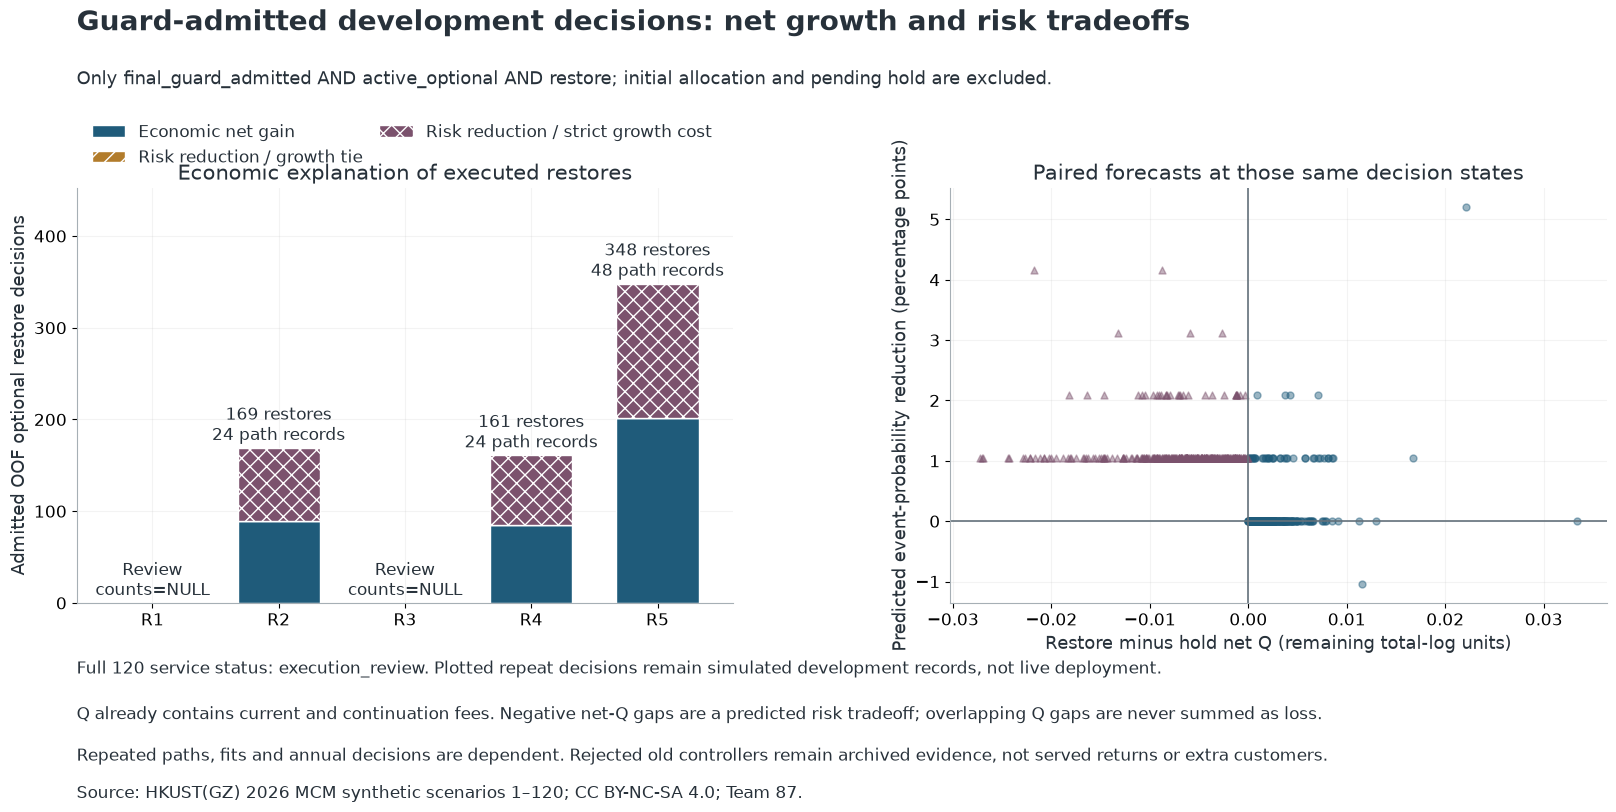

In [9]:
def plot_trade_attribution(trade_counts,served_trades,full):
    import numpy as np
    import matplotlib.pyplot as plt
    plot_style();fig,axes=plt.subplots(1,2,figsize=(17,8.3));fig.subplots_adjust(left=.065,right=.965,bottom=.26,top=.76,wspace=.33)
    left,right=axes;x=np.arange(5);colors=['#1f5b7a','#b27c2b','#7b526d'];names=['Economic net gain','Risk reduction / growth tie','Risk reduction / strict growth cost']
    bottom=np.zeros(5);valid=trade_counts.admitted_path_records.gt(0).to_numpy()
    for column,label,color,hatch in [('economic_gain',names[0],colors[0],None),('risk_tie',names[1],colors[1],'//'),('growth_cost',names[2],colors[2],'xx')]:
        values=trade_counts[column].fillna(0).to_numpy(float);left.bar(x[valid],values[valid],.65,bottom=bottom[valid],color=color,label=label,hatch=hatch,edgecolor='white');bottom+=values
    high=max(1,float(bottom.max()))
    for j,row in enumerate(trade_counts.itertuples()):
        text='Review\ncounts=NULL' if row.admitted_path_records==0 else f'{int(row.optional_restores)} restores\n{row.admitted_path_records} path records'
        left.text(j,(high*.025 if row.admitted_path_records==0 else bottom[j]+high*.025),text,ha='center',fontsize=12)
    left.set(xticks=x,xticklabels=[f'R{i}' for i in range(1,6)],xlim=(-.6,4.6),ylim=(0,high*1.3),ylabel='Admitted OOF optional restore decisions',title='Economic explanation of executed restores')
    left.legend(loc='upper left',bbox_to_anchor=(0,1.19),frameon=False,ncol=2,columnspacing=1.)
    if len(served_trades):
        for label,color,marker in zip(names,colors,['o','s','^']):
            selected=served_trades.loc[served_trades.trade_class.eq(label)]
            if len(selected):right.scatter(selected.delta_net_total_log_growth,-100*selected.delta_model_breach_probability,s=25,alpha=.45,color=color,marker=marker,label=label)
        right.axvline(0,color='#64717b',linewidth=1.2);right.axhline(0,color='#64717b',linewidth=1.2)
        right.set(xlabel='Restore minus hold net Q (remaining total-log units)',ylabel='Predicted event-probability reduction (percentage points)',title='Paired forecasts at those same decision states')
    else:
        right.axis('off');right.text(.5,.5,'No final-admitted optional restores\nQ distribution unavailable',ha='center',va='center',transform=right.transAxes,fontsize=15)
    for ax in axes:ax.spines[['top','right']].set_visible(False);ax.grid(alpha=.15);ax.set_axisbelow(True)
    fig.text(.065,.95,'Guard-admitted development decisions: net growth and risk tradeoffs',fontsize=20,weight='bold')
    fig.text(.065,.885,'Only final_guard_admitted AND active_optional AND restore; initial allocation and pending hold are excluded.',fontsize=13)
    fig.text(.065,.175,f'Full 120 service status: {full["execution_status"]}. Plotted repeat decisions remain simulated development records, not live deployment.',fontsize=12)
    fig.text(.065,.12,'Q already contains current and continuation fees. Negative net-Q gaps are a predicted risk tradeoff; overlapping Q gaps are never summed as loss.',fontsize=12)
    fig.text(.065,.07,'Repeated paths, fits and annual decisions are dependent. Rejected old controllers remain archived evidence, not served returns or extra customers.',fontsize=12)
    fig.text(.065,.025,SOURCE_NOTE,fontsize=12)
    return fig

fig=plot_trade_attribution(tables['trade_counts'],tables['served_trades'],tables['full'])
display(fig)
plt.close(fig)

In [10]:
show(tables['trade_counts'])
archived=tables['trades']
archive_scope=archived.groupby(['repeat_id','final_guard_admitted'],dropna=False).agg(
    archived_path_records=('scenario_id','size'),original_contexts=('context','nunique')).reset_index()
archive_scope=archive_scope.rename(columns={'archived_path_records':'年度决策记录数_非客户数'})
show(archive_scope)
admitted=tables['clients'].loc[tables['clients'].policy.eq(POLICY)&tables['clients'].assigned&tables['clients'].repeat_id.between(1,5)]
print(f'获准OOF记录共{len(admitted)}条，对应{admitted.scenario_id.nunique()}个不同原市场ID；它们不是独立新客户。只按重复保留描述统计，不累加forecast Q缺口。')

repeat_id,admitted_path_records,optional_restores,economic_gain,risk_tie,growth_cost
1,0,NULL,NULL,NULL,NULL
2,24,169.000000,89.000000,0.000000,80.000000
3,0,NULL,NULL,NULL,NULL
4,24,161.000000,85.000000,0.000000,76.000000
5,48,348.000000,202.000000,0.000000,146.000000


repeat_id,final_guard_admitted,年度决策记录数_非客户数,original_contexts
0,False,3600,1
2,False,720,1
2,True,720,1
3,False,3600,5
4,False,1440,2
4,True,720,1
5,True,1440,2


获准OOF记录共96条，对应74个不同原市场ID；它们不是独立新客户。只按重复保留描述统计，不累加forecast Q缺口。


## 9. 收敛的是框架与准入判断

当前保留的是完整策略约束、有限技术控制器、覆盖优先内层top-E与明确拒绝选项的数学程序，额外same-U guard只收紧准入。它不消除参数/目标不唯一、跨拟合不稳定、无条件calendar预测近似、有限尾部样本和反复开发的局限。

全开发C如果仍为Review，准确结论是当前固定规则与证据**尚不支持自动C部署**。部分外层fit获准、代码审计通过、甚至完整训练可行，都不能替代这一结论，也不能推出一切安全盈利策略不存在。主框架收敛不等于已经获得可部署投资策略。下一步应解释假设、证据和局限，而不是为覆盖率改阈值、换beta/eta或回填参考收益。

本companion保存三张可追溯科研图与可编辑绘图代码，等待实际PNG检查后执行。HTML仅承诺执行和静态输出检查，不声称整个HTML的浏览器视觉预览通过。论文仍未生成或提交。

In [11]:
end=companion.require_complete(ROOT)
assert ready['input_artifact_sha256']==end['input_artifact_sha256']
selected=[companion.PROTOCOL,companion.STUDY/'manifest.json',companion.STUDY/'independent_audit.json',
    companion.STUDY/'admission.csv.gz',companion.STUDY/'summary.csv.gz',companion.STUDY/'trade_estimates.csv.gz',
    Path('scripts/build_final_model_notebook.py'),companion.FIGURES/'manifest.json']
show(pd.DataFrame([{'来源路径':str(path),'SHA256':companion.sha(ROOT/path)} for path in selected]))
print('完整来源映射存于科研图manifest；起止相同。没有市场解析、新拟合、替换准入或paper写入。')

来源路径,SHA256
docs/global_policy_admission_protocol.json,5b3c2fa27300774f24d0195e4817ad3fd5e662f30cf3deffbd29cdc3d5cb0bd0
results/model_review/global_policy_admission_v1/manifest.json,5b6449d949999458abe5ea6b8f47a74139ae0bf1699883bf5c8da7646c31c749
results/model_review/global_policy_admission_v1/independent_audit.json,9f85f41112ac59a42f721c84808704cae980ca9cba61d63458ffe2018c77d8b0
results/model_review/global_policy_admission_v1/admission.csv.gz,b839933592a506a0b4d311b80da1fba0fd354088ea8bebc54c8128f4a46f78ee
results/model_review/global_policy_admission_v1/summary.csv.gz,a8108b91378c2db4be72d7e3e2aa5c57c661b4d55af9e675993835e1d4f77684
results/model_review/global_policy_admission_v1/trade_estimates.csv.gz,e2f41f619c873096da8ebcf6d7c10e49b2c302bb6655a21d45420938067fda8c
scripts/build_final_model_notebook.py,230bb57591681e200b3c9df2c54283cd413c926ef264d6448b7bea59841f2734
research/figures/final_model_development/manifest.json,405caf326573c7bcd33a853da5378b24f977aba50eed38609700c78fcfa6b8df


完整来源映射存于科研图manifest；起止相同。没有市场解析、新拟合、替换准入或paper写入。
